# Fields and cuts

A simulation result means little without its geometry. It matters where the hot spot is, which wall carries the
flux, and what the field looks like in a plane through the bore. `px.PlotField(field, mesh, obj)` draws a field **on
the planex2d geometry it was computed on**, in 2D, with matplotlib or plotly, and `px.PlotMesh(mesh, obj)` draws the
mesh. The field can come from NGSolve, as a `GridFunction` or any `CoefficientFunction`, or from FEniCSx, as a dolfinx
`Function`. The examples on this page use NGSolve.

| Call or keyword | What it draws |
|---|---|
| `px.PlotField(field, obj)` | The field as colors over the faces (its magnitude for vectors) |
| `px.PlotField(field, mesh, obj)` | The same for a `CoefficientFunction`, evaluated on `mesh` |
| `px.PlotMesh(mesh, obj)` | The element edges, curved where the mesh is curved |
| `vectors=True` | Arrows of a vector field |
| `field_lines=True` or a density | The field lines of a vector field |
| `contours=n` or a list | Contour lines at n levels or at the given values |
| `min=`, `max=` | The color range, as in NGSolve's `Draw` |
| `colormap=` | `"default"` (the planex2d map, from low in red to high in blue), `"default_r"`, any matplotlib name, or a list of colors |

A 3D result can be drawn in any plane. Either cut the solid with `px.Intersect3d` and plot the field on the cut, or
pass the cutting plane to `px.PlotField` as `obj`.

Every value shown is the field at that pixel's point, with no interpolation between mesh nodes, and only where both
the geometry and the mesh are present, so a pixel that the mesh does not cover stays empty. Every section ends with a
check against a known number.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import netgen.occ as occ
import ngsolve as ngs
import numpy as np
import planex as px
import planex.measurements as pm

mm = px.mm


def solve(fes, a, f=None, boundary=None):
    gf = ngs.GridFunction(fes)
    if boundary is not None:
        gf.Set(boundary, ngs.BND)
    a.Assemble()
    r = -a.mat * gf.vec
    if f is not None:
        f.Assemble()
        r += f.vec
    gf.vec.data += a.mat.Inverse(fes.FreeDofs()) * r
    return gf

In [2]:
import warnings

warnings.simplefilter("ignore", px.PlanexWarning)

The helper `solve` has NGSolve solve `a(u, v) = f(v)` with the Dirichlet values `boundary`, a `CoefficientFunction`
on the boundary.

## A temperature field on a part

The example is an aluminum cooling plate, 120 × 60 mm, with k = 200 W/(m K). A 30 mm heater pad on its bottom edge
puts in 400 W per meter of depth, two coolant channels at 20 °C take it out, and all other edges are insulated. The
edges carry their names from the sketch, so the boundary conditions refer to `"heater"` and `"coolant"`, not to edge
numbers.

In [3]:
k = 200.0
P = 400.0

s = px.QuickSketch().Line(45 * mm, name="air").Line(30 * mm, name="heater").Line(45 * mm, name="air")
s.Line(0, 60 * mm, name="air").Line(-120 * mm, 0, name="air").Close(name="air")
s.Circle(30 * mm, 40 * mm, 6 * mm, name="coolant").Circle(90 * mm, 40 * mm, 6 * mm, name="coolant")
plate = s.Face()

mesh = ngs.Mesh(px.OCCGeometry(plate).GenerateMesh(maxh=4 * mm))
mesh.Curve(3)
fes = ngs.H1(mesh, order=3, dirichlet="coolant")
T, v = fes.TnT()
a = ngs.BilinearForm(k * ngs.grad(T) * ngs.grad(v) * ngs.dx)
f = ngs.LinearForm(P / (30 * mm) * v * ngs.ds("heater"))
gfT = solve(fes, a, f, mesh.BoundaryCF({"coolant": 20.0}, default=0))
print(mesh.ne, "elements, boundaries", sorted(set(mesh.GetBoundaries())))

999 elements, boundaries ['air', 'coolant', 'heater']


The temperature is shown with 12 contour lines, next to the mesh it was computed on. The planex2d color map runs
from red (low) to blue (high), the convention of these docs, where low values are critical, as for a thin wall. For a
temperature, hot should be red, so these plots use `colormap="default_r"`. `px.PlotMesh` draws the element edges,
curved like the mesh.

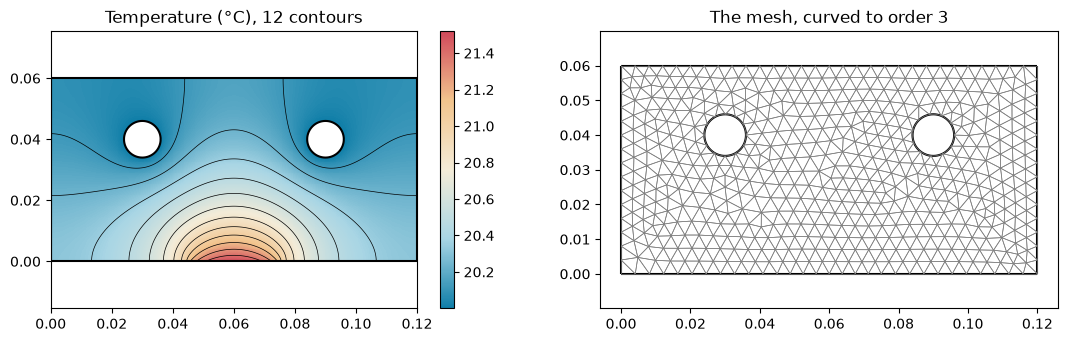

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.6))
px.PlotField(gfT, plate, ax=left, colormap="default_r", contours=12)
left.set_title("Temperature (°C), 12 contours")
px.PlotMesh(mesh, plate, ax=right, legend=False)
right.set_title("The mesh, curved to order 3")
plt.show()

The heat flux `-k grad T` is a vector field, and the color shows its magnitude. `vectors=True` adds arrows, and
`field_lines=True` adds the lines the heat follows from the pad into the channels. A `CoefficientFunction` like this
one has no mesh of its own, so the mesh is the second argument of `px.PlotField`.

**Check:** what the pad puts in must leave through the channels. On a boundary, NGSolve's `grad` is the gradient
along the boundary, so the normal flux needs `BoundaryFromVolumeCF`.

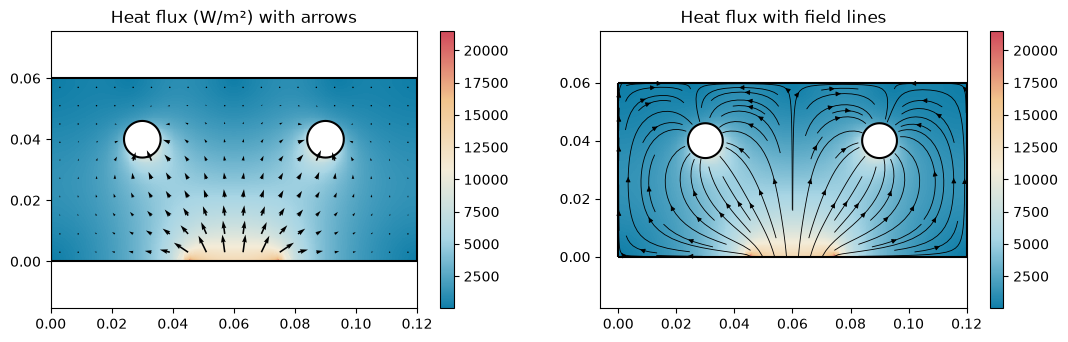

in through the heater 400.0 W/m, out through the channels 399.78 W/m
difference 0.0005378832993086746 of the power


In [5]:
flux = -k * ngs.grad(gfT)
shown = {"colormap": "default_r"}
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.6))
px.PlotField(flux, mesh, plate, ax=left, vectors=True, **shown)
left.set_title("Heat flux (W/m²) with arrows")
px.PlotField(flux, mesh, plate, ax=right, field_lines=True, **shown)
right.set_title("Heat flux with field lines")
plt.show()

n = ngs.specialcf.normal(2)
normal_flux = ngs.InnerProduct(ngs.BoundaryFromVolumeCF(flux), n)
out = ngs.Integrate(normal_flux, mesh, definedon=mesh.Boundaries("coolant"))
print("in through the heater", P, "W/m, out through the channels", round(out, 2), "W/m")
print("difference", abs(out - P) / P, "of the power")

## An exact check: a pipe wall

A pipe wall between the radii 10 and 25 mm, at 90 °C inside and 20 °C outside, has the exact temperature
T(r) = T_i + (T_o − T_i) ln(r / r_i) / ln(r_o / r_i). The plot shows the **error** of the finite element solution,
`gf - exact`, a `CoefficientFunction` like any other. With a symmetric `min` and `max` the default map works as a
diverging one, where the cream middle means no error, red too cold and blue too warm.

The walls are circles, so it matters how well the mesh follows them. A straight mesh (`Curve(1)`) replaces each
circle by a polygon. Between the polygon and the true circle, there is geometry but no mesh, and those pixels stay
**empty** instead of showing an extrapolated value. A curved mesh (`Curve(3)`) fills the circle.

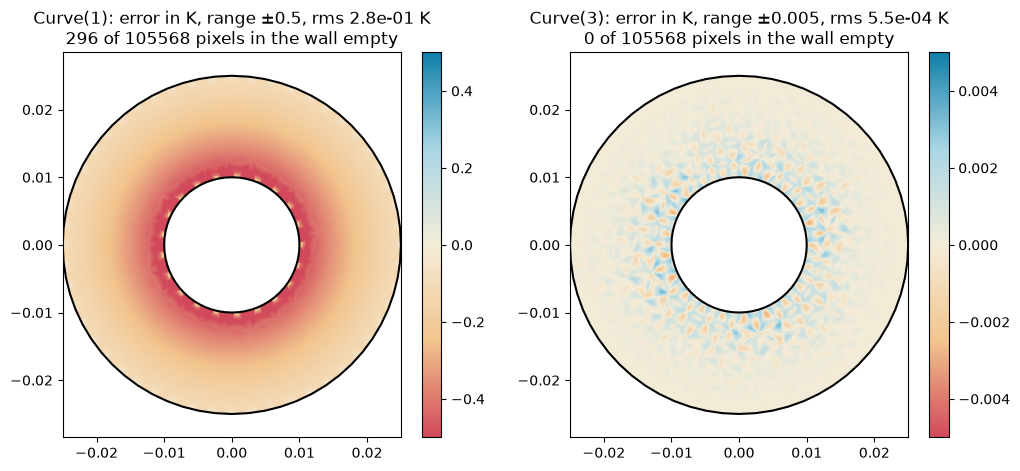

In [6]:
ri, ro = 10 * mm, 25 * mm
Ti, To = 90.0, 20.0
wall = px.QuickSketch().Circle(0, 0, ro, name="outside").Circle(0, 0, ri, name="inside").Face()
r = ngs.sqrt(ngs.x ** 2 + ngs.y ** 2)
exact = Ti + (To - Ti) * ngs.log(r / ri) / math.log(ro / ri)


def pipe_solution(curve):
    m = ngs.Mesh(px.OCCGeometry(wall).GenerateMesh(maxh=3 * mm))
    m.Curve(curve)
    space = ngs.H1(m, order=3, dirichlet="inside|outside")
    u, w = space.TnT()
    a = ngs.BilinearForm(ngs.grad(u) * ngs.grad(w) * ngs.dx)
    held = m.BoundaryCF({"inside": Ti, "outside": To})
    return m, solve(space, a, boundary=held)


def empty_pixels(ax, shape):
    image = ax.get_images()[0]
    z = np.ma.filled(image.get_array().astype(float), np.nan)
    x0, x1, y0, y1 = image.get_extent()
    xs = x0 + (np.arange(z.shape[1]) + 0.5) * (x1 - x0) / z.shape[1]
    ys = y0 + (np.arange(z.shape[0]) + 0.5) * (y1 - y0) / z.shape[0]
    gx, gy = np.meshgrid(xs, ys)
    points = np.c_[gx.ravel(), gy.ravel()]
    inside = shape.Contains(points, boundary=False).reshape(z.shape)
    return int((inside & np.isnan(z)).sum()), int(inside.sum())


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, curve, limit in zip(axes, (1, 3), (0.5, 0.005)):
    m, gf = pipe_solution(curve)
    rms = math.sqrt(ngs.Integrate((gf - exact) ** 2, m) / ngs.Integrate(1, m))
    px.PlotField(gf - exact, m, wall, ax=ax, min=-limit, max=limit)
    empty, total = empty_pixels(ax, wall)
    ax.set_title(f"Curve({curve}): error in K, range ±{limit}, "
                 f"rms {rms:.1e} K\n"
                 f"{empty} of {total} pixels in the wall empty")
plt.show()

`empty_pixels` counts the pixels whose center lies in the wall but that show nothing. Zoomed in on the inner wall of
the straight mesh, the empty crescents are where the polygon cuts the circle, and no value is invented there.
`px.PlotMesh` on the same axes draws the mesh on top.

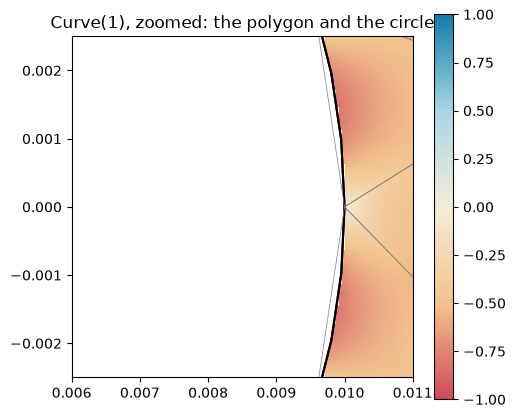

In [7]:
m1, gf1 = pipe_solution(1)
fig, ax = plt.subplots(figsize=(5.5, 5))
px.PlotField(gf1 - exact, m1, wall, ax=ax, min=-1, max=1, samples=1200)
px.PlotMesh(m1, wall, ax=ax, legend=False)
ax.set_xlim(6 * mm, 11 * mm)
ax.set_ylim(-2.5 * mm, 2.5 * mm)
ax.set_aspect("equal", adjustable="box")
ax.set_title("Curve(1), zoomed: the polygon and the circle")
plt.show()

**Check:** the heat flows radially, so every field line must point at the center. The lines are the ones `px.PlotField`
drew, which matplotlib keeps in the axes; the angle between each piece of a line and the radius is measured.

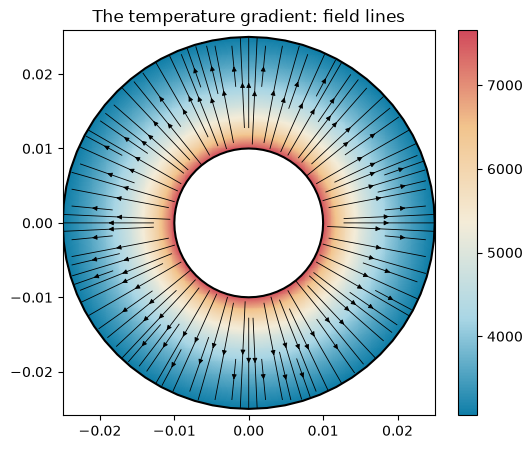

981 steps along the field lines, largest angle to the radius 0.057 degrees


In [8]:
m3, gf3 = pipe_solution(3)
fig, ax = plt.subplots(figsize=(6, 5))
px.PlotField(-ngs.grad(gf3), m3, wall, ax=ax, colormap="default_r", field_lines=1.5)
ax.set_title("The temperature gradient: field lines")
plt.show()

lines = [c for c in ax.collections if c.get_gid() == "field lines"][0]
worst, steps = 0.0, 0
for line in lines.get_segments():
    for p, q in zip(line[:-1], line[1:]):
        d, mid = q - p, (p + q) / 2
        if np.hypot(*d) > 1e-9:
            steps += 1
            cross = d[0] * mid[1] - d[1] * mid[0]
            sine = cross / np.hypot(*d) / np.hypot(*mid)
            worst = max(worst, math.degrees(abs(math.asin(sine))))
print(steps, "steps along the field lines, largest angle to the radius", round(worst, 3), "degrees")

## `min` and `max` at a re-entrant corner

An L-shaped plate is held at 0 on its long bottom edge and at 1 on the top of the short leg. At the inner corner, the
gradient is singular: it grows like r^(−1/3) towards the corner, without bound as the mesh is refined there.
`plate_L.vertices(near=corner).maxh` gives the corner vertex a small mesh size, which goes onto the OpenCASCADE vertex,
and netgen grades the mesh towards it. With the color range taken from the values,
the corner is all that can be seen. `max=` fixes the range, so the rest of the plate gets the colors, and the contours
follow the same range.

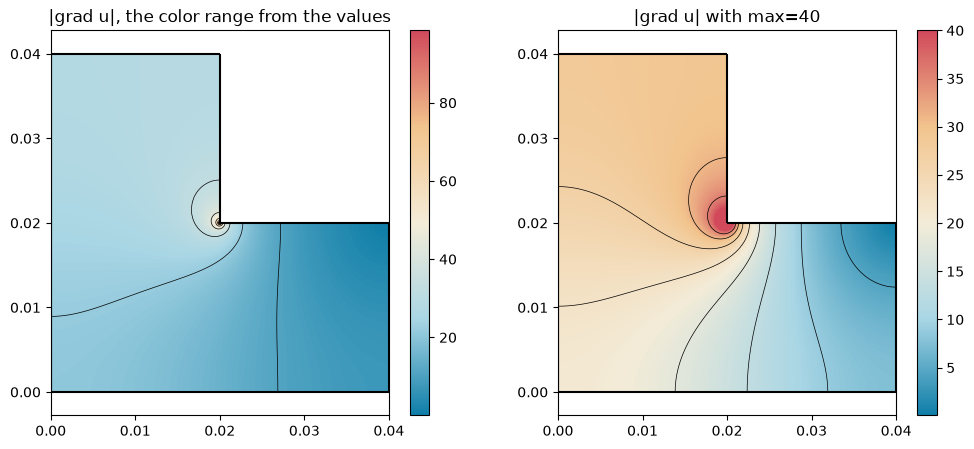

|grad u| 1 mm from the corner, on the diagonal: 41
|grad u| 0.1 mm from the corner, on the diagonal: 88
|grad u| 0.01 mm from the corner, on the diagonal: 147
843 elements; the pixels: largest 99 and 99 % of them below 35


In [9]:
s = px.QuickSketch().Line(40 * mm, 0, name="cold").Line(0, 20 * mm).Line(-20 * mm, 0)
plate_L = s.Line(0, 20 * mm).Line(-20 * mm, 0, name="hot").Close().Face()
plate_L.vertices(near=(20 * mm, 20 * mm)).maxh = 0.05 * mm
mesh_L = ngs.Mesh(px.OCCGeometry(plate_L).GenerateMesh(maxh=2 * mm))
space_L = ngs.H1(mesh_L, order=3, dirichlet="cold|hot")
u, w = space_L.TnT()
a = ngs.BilinearForm(ngs.grad(u) * ngs.grad(w) * ngs.dx)
u_L = solve(space_L, a, boundary=mesh_L.BoundaryCF({"hot": 1.0}, default=0))
gradient = ngs.Norm(ngs.grad(u_L))

shown = {"colormap": "default_r", "contours": 8}
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 5))
px.PlotField(gradient, mesh_L, plate_L, ax=left, **shown)
left.set_title("|grad u|, the color range from the values")
px.PlotField(gradient, mesh_L, plate_L, ax=right, max=40, **shown)
right.set_title("|grad u| with max=40")
plt.show()

for d in (1, 0.1, 0.01):
    x = y = 20 * mm - d * mm / 2 ** 0.5
    value = gradient(mesh_L(x, y))
    print("|grad u|", d, "mm from the corner, on the diagonal:", round(value))
values = np.ma.filled(left.get_images()[0].get_array().astype(float), np.nan)
print(mesh_L.ne, "elements; the pixels: largest", round(np.nanmax(values)), "and 99 % of them below",
      round(np.nanpercentile(values, 99)))

## Cutting a 3D part

The example is an aluminum block, 80 × 40 × 30 mm, with a bore of 6 mm radius held at 80 °C. Its right face sits on
a heat sink at 20 °C, and the other faces lose heat to the air at 15 W/(m² K). The result lives on a tetrahedral
mesh. To look inside, the solid is cut with `px.Intersect3d`. The cut is a planex2d shape on the cutting plane, and
`px.PlotField` evaluates the 3D field at each pixel's 3D point. `px.PlotMesh` with the 3D mesh draws where the plane
cuts the elements.

In [10]:
block = occ.Box(occ.Pnt(0, 0, 0), occ.Pnt(80 * mm, 40 * mm, 30 * mm))
bore = occ.Cylinder(occ.Pnt(20 * mm, 20 * mm, 0), occ.Z, r=6 * mm, h=30 * mm)
part = block - bore
part.faces.name = "air"
part.faces.Nearest(occ.Pnt(26 * mm, 20 * mm, 15 * mm)).name = "bore"
part.faces.Max(occ.X).name = "sink"

mesh3 = ngs.Mesh(occ.OCCGeometry(part).GenerateMesh(maxh=4 * mm))
mesh3.Curve(2)
space3 = ngs.H1(mesh3, order=2, dirichlet="bore|sink")
u, w = space3.TnT()
a = ngs.BilinearForm(200 * ngs.grad(u) * ngs.grad(w) * ngs.dx + 15 * u * w * ngs.ds("air"))
held = mesh3.BoundaryCF({"bore": 80.0, "sink": 20.0}, default=0)
T3 = solve(space3, a, boundary=held)
print(mesh3.ne, "tetrahedra")

6794 tetrahedra


The cutting plane is a `px.Plane` through the middle of the block, tilted about the x axis. Every plane argument in
planex2d also takes netgen's `occ.Axes`, so netgen code can pass its axes unchanged.

In [11]:
oblique = px.Plane(origin=(40 * mm, 20 * mm, 15 * mm), normal=(0, 0.6, 1), axis=(1, 0, 0))

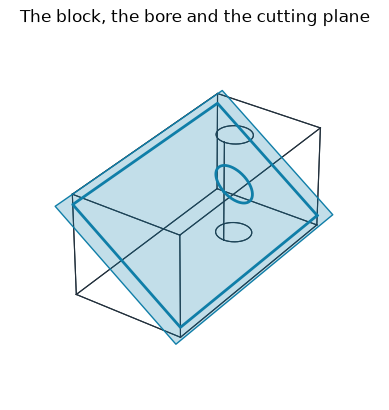

In [12]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

origin, dh, dv = (np.array(a) for a in (oblique.origin, oblique.h, oblique.v))


def on_plane(hv):
    return origin + hv[:, :1] * dh + hv[:, 1:] * dv


fig = plt.figure(figsize=(7, 4.8))
view = fig.add_subplot(projection="3d")
for edge in part.edges:
    t0, t1 = edge.parameter_interval
    p = np.array([[q.x, q.y, q.z] for q in map(edge.Value, np.linspace(t0, t1, 40))])
    view.plot(*p.T, color="#22303c", lw=0.8)
half_h, half_v = 46 * mm, 26 * mm
square = [(-half_h, -half_v), (half_h, -half_v), (half_h, half_v), (-half_h, half_v)]
view.add_collection3d(Poly3DCollection([on_plane(np.array(square))], facecolor="#0f7ea8", edgecolor="#0f7ea8",
                                       alpha=0.25))
for loop in px.Intersect3d(oblique, part).Polylines(0.05 * mm):
    view.plot(*on_plane(loop).T, color="#0f7ea8", lw=2)
view.set_box_aspect((80, 40, 30))
view.view_init(elev=32, azim=35)
view.set_axis_off()
view.set_title("The block, the bore and the cutting plane")
plt.show()

`px.PlotField(field, plane)` cuts the geometry that the field's mesh was made from (the mesh remembers its
OpenCASCADE shape) and draws the field on that cut:

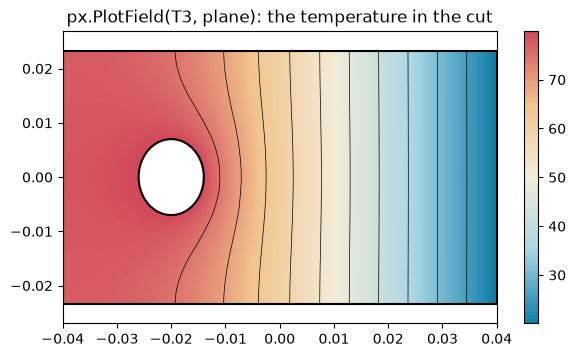

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.8))
px.PlotField(T3, oblique, ax=ax, colormap="default_r", contours=10)
ax.set_title("px.PlotField(T3, plane): the temperature in the cut")
plt.show()

The same cut can also be made as an
explicit planex2d shape with `px.Intersect3d(plane, part)`. The plots show it with the 3D mesh drawn where the plane
cuts its elements, and with the heat flux, whose field lines follow its component in the plane:

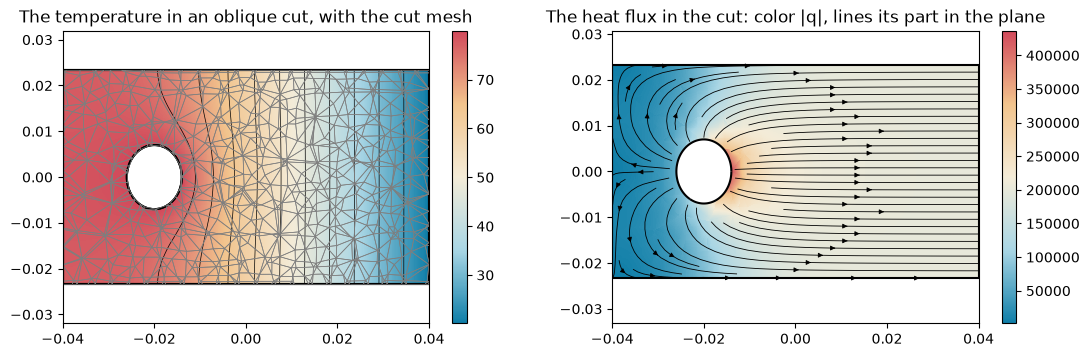

In [14]:
cut = px.Intersect3d(oblique, part)
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.8))
px.PlotField(T3, cut, ax=left, colormap="default_r", contours=10)
px.PlotMesh(mesh3, cut, ax=left, legend=False)
left.set_title("The temperature in an oblique cut, with the cut mesh")
px.PlotField(-200 * ngs.grad(T3), mesh3, cut, ax=right, colormap="default_r", field_lines=True)
right.set_title("The heat flux in the cut: color |q|, lines its part in the plane")
plt.show()

**Checks:** a cut at mid-height parallel to the base is the rectangle minus the bore's circle, so its area is known
exactly. Every pixel shows the field at its 3D point, so a pixel compared with NGSolve's own evaluation at that point
must agree up to rounding.

cut area 3086.9026644707674 mm², exact 3086.9026644707674 mm²


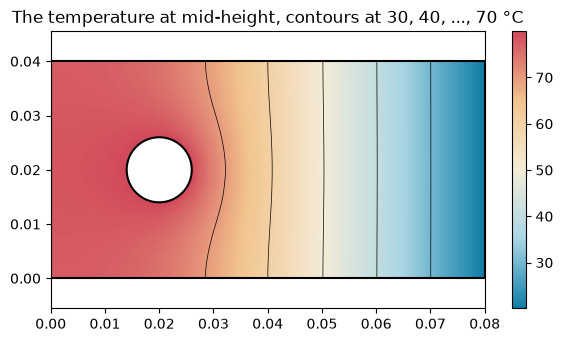

the pixel at (60.1, 20.1, 15.0) mm: 40.08146220784872 °C
NGSolve there: 40.08146220784871 °C


In [15]:
mid = px.Intersect3d(px.XY.Offset(15 * mm), part)
print("cut area", mid.mass * 1e6, "mm², exact", 80 * 40 - math.pi * 36, "mm²")

fig, ax = plt.subplots(figsize=(7, 3.6))
px.PlotField(T3, mid, ax=ax, colormap="default_r", contours=[30, 40, 50, 60, 70])
ax.set_title("The temperature at mid-height, contours at 30, 40, ..., 70 °C")
plt.show()

image = ax.get_images()[0]
z = np.ma.filled(image.get_array().astype(float), np.nan)
x0, x1, y0, y1 = image.get_extent()
j, i = z.shape[0] // 2, z.shape[1] * 3 // 4
pu = x0 + (i + 0.5) * (x1 - x0) / z.shape[1]
pv = y0 + (j + 0.5) * (y1 - y0) / z.shape[0]
x, y, zz = mid.ToXYZ((pu, pv))
there = T3(mesh3(x, y, zz))
print("the pixel at", (round(x / mm, 3), round(y / mm, 3), round(zz / mm, 3)), "mm:", z[j, i], "°C")
print("NGSolve there:", there, "°C")

## Contours on a measurement

`contours=`, `min` and `max` work on every color plot, including the planex2d
[measurements](../../core/measuring/index.md). The example shows the minimum thickness of an L bracket, the diameter of
the largest disc that fits at each point of the boundary, with the color range fixed to the 8 mm wall and the 14 mm
corner. A sharp convex corner is infinitely thin by this definition, so `ignore_corners=91` leaves out the bracket's
90° corners.

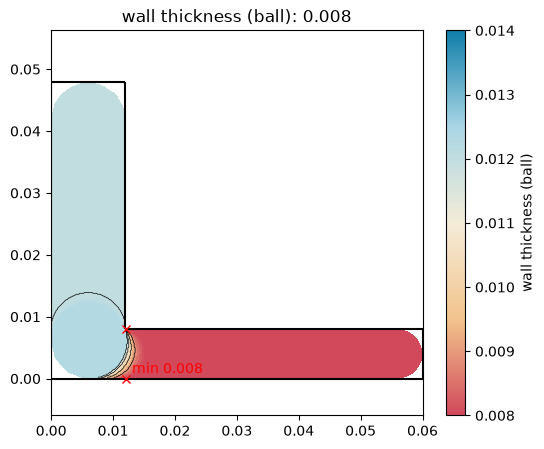

In [16]:
s = px.QuickSketch().Line(60 * mm, 0).Line(0, 8 * mm).Line(-48 * mm, 0).Line(0, 40 * mm)
bracket = s.Line(-12 * mm, 0).Close().Face()
fig, ax = plt.subplots(figsize=(6, 5))
thickness = pm.MinThickness(ignore_corners=91)
px.PlotField(thickness, bracket, ax=ax, contours=5, min=8 * mm, max=14 * mm)
plt.show()

## Interactive, and how long it takes

`backend="plotly"`, or a plotly figure as `ax`, draws the same with zoom and the value under the mouse. As for the
cost, every plot evaluates the field once per pixel, with 400 pixels along the longer side by default, and `samples=`
changes that.

In [17]:
fig = px.PlotField(T3, cut, colormap="default_r", contours=10, backend="plotly", samples=150)
fig.update_layout(title="The oblique cut, interactive")
fig.show()

hot = {"colormap": "default_r"}
plots = {
    "plate: temperature, 12 contours":
        lambda: px.PlotField(gfT, plate, contours=12, **hot),
    "plate: flux, field lines":
        lambda: px.PlotField(flux, mesh, plate, field_lines=True, **hot),
    "3D cut: temperature, 10 contours":
        lambda: px.PlotField(T3, cut, contours=10, **hot),
    "3D cut: the cut mesh": lambda: px.PlotMesh(mesh3, cut, legend=False),
}
for label, draw in plots.items():
    t = time.perf_counter()
    draw()
    plt.close("all")
    print(label, round(time.perf_counter() - t, 2), "s")

plate: temperature, 12 contours 0.21 s


plate: flux, field lines 0.53 s


3D cut: temperature, 10 contours 0.68 s
3D cut: the cut mesh 0.17 s
